# Inspect the JAKA MiniCobo friction dataset

This notebook checks the two downloaded files, previews their columns, reports basic quality statistics, and plots a short signal sample.

In [2]:
%pip install -q pandas matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from openpyxl import load_workbook

project_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_dir = project_dir / 'data' / 'raw' / 'jaka_minicobo_friction'
csv_path = next(data_dir.rglob('data.csv'))
excel_path = next(data_dir.rglob('13h.xlsx'))

csv_rows = sum(1 for _ in csv_path.open('rb')) - 1
workbook = load_workbook(excel_path, read_only=True, data_only=True)
excel_rows = workbook.active.max_row - 1
workbook.close()

print(f'CSV:   {csv_path.name} | {csv_rows:,} rows | {csv_path.stat().st_size / 1_000_000:.1f} MB')
print(f'Excel: {excel_path.name} | {excel_rows:,} rows | {excel_path.stat().st_size / 1_000_000:.1f} MB')

CSV:   data.csv | 8,952,720 rows | 241.6 MB
Excel: 13h.xlsx | 677,110 rows | 42.5 MB


In [4]:
sample_size = 50_000
csv_sample = pd.read_csv(csv_path, nrows=sample_size)
excel_sample = pd.read_excel(excel_path, nrows=sample_size)

for name, frame in [('data.csv', csv_sample), ('13h.xlsx', excel_sample)]:
    print(f'\n{name}: shape={frame.shape}')
    print('Columns:', list(frame.columns))
    display(frame.head())
    display(frame.dtypes.rename('dtype').to_frame())
    display(frame.isna().sum().rename('missing').to_frame())
    display(frame.describe().T.round(4))


data.csv: shape=(50000, 4)
Columns: ['Velocity', 'Tau_G', 'Temperature', 'Friction']


,Velocity,Tau_G,Temperature,Friction
0,0.002,2.920805,55,1.019287
1,-0.002,2.920805,55,-1.019287
2,0.002,2.920595,55,0.999451
3,-0.002,2.920595,55,-0.999451
4,0.002,2.920609,55,0.901794


,dtype
Velocity,float64
Tau_G,float64
Temperature,int64
Friction,float64


,missing
Velocity,0
Tau_G,0
Temperature,0
Friction,0


,count,mean,std,min,25%,50%,75%,max
Velocity,50000.0,0.0000,0.0020,-0.0020,-0.0020,0.0000,0.0020,0.0020
Tau_G,50000.0,2.4542,0.2846,1.9643,2.2026,2.4743,2.7018,2.9208
Temperature,50000.0,54.0318,1.5288,51.0000,52.0000,55.0000,55.0000,55.0000
Friction,50000.0,0.0000,1.3167,-4.2938,-0.9506,0.0000,0.9506,4.2938



13h.xlsx: shape=(50000, 5)
Columns: ['Velocity', 'Tau_G', 'Temperature', 'Friction', 'Time_s']


,Velocity,Tau_G,Temperature,Friction,Time_s
0,-0.316925,-0.000144,54,0.248981,0.000000
1,-0.612224,0.007795,54,-1.690896,0.031663
2,-0.270377,0.010855,54,-1.988336,0.048234
3,-0.197506,0.013451,54,-1.908823,0.079892
4,-0.250318,0.017477,54,-2.055380,0.128181


,dtype
Velocity,float64
Tau_G,float64
Temperature,int64
Friction,float64
Time_s,float64


,missing
Velocity,0
Tau_G,0
Temperature,0
Friction,0
Time_s,0


,count,mean,std,min,25%,50%,75%,max
Velocity,50000.0,-0.0067,0.5602,-2.1968,-0.3380,-0.1127,0.3012,2.6121
Tau_G,50000.0,1.3831,7.7676,-13.4238,-4.6750,2.0779,7.1965,14.0815
Temperature,50000.0,57.0322,1.8335,54.0000,56.0000,57.0000,58.0000,61.0000
Friction,50000.0,-0.5015,2.4588,-4.5937,-2.4366,-1.8308,2.0913,4.2332
Time_s,50000.0,2048.7828,1187.0997,0.0000,1074.6338,1976.8022,3232.0501,3949.1478


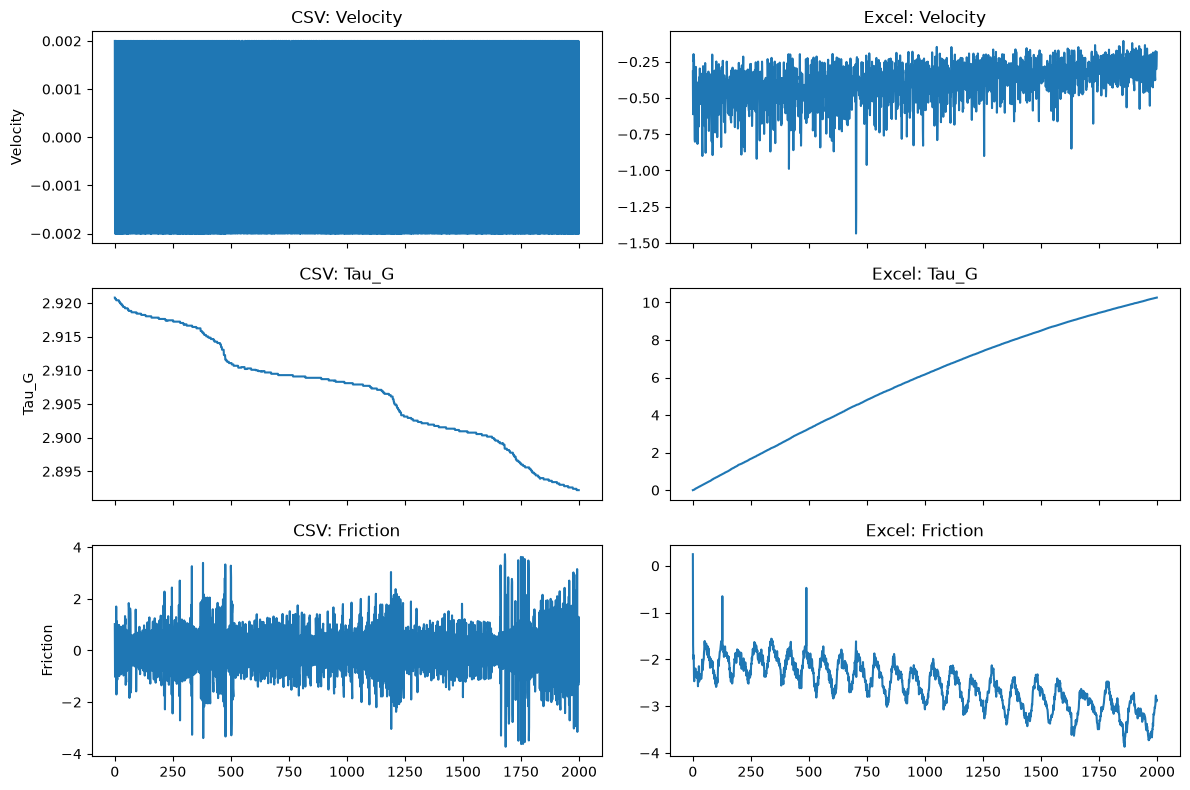

In [5]:
signals = ['Velocity', 'Tau_G', 'Friction']
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex='col')
for column, row in zip(signals, axes):
    row[0].plot(csv_sample[column].iloc[:2_000])
    row[0].set_title(f'CSV: {column}')
    row[1].plot(excel_sample[column].iloc[:2_000])
    row[1].set_title(f'Excel: {column}')
    row[0].set_ylabel(column)
plt.tight_layout()
plt.show()

In [6]:
print('Inspection notes:')
print('- Both files contain velocity, motor torque (Tau_G), temperature, and friction.')
print('- 13h.xlsx also includes Time_s, so it can support time-series and degradation analysis.')
print('- The friction signal is the target for a friction-model or anomaly-data generator.')
print('- Use this dataset to model friction behaviour; it does not directly label bearing, gearbox, or collision faults.')

Inspection notes:
- Both files contain velocity, motor torque (Tau_G), temperature, and friction.
- 13h.xlsx also includes Time_s, so it can support time-series and degradation analysis.
- The friction signal is the target for a friction-model or anomaly-data generator.
- Use this dataset to model friction behaviour; it does not directly label bearing, gearbox, or collision faults.
